# Mercado global - UD Las Palmas 26/27

## Librería

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

## Variables

In [ ]:
RUTA_SCOUTING = Path.cwd().parent.parent / 'data' / 'scout'
CARPETAS_MERCADO = ['1rfef', 'ligas', 'sub_23']

MINUTOS_MINIMOS = 500
LIMITE_INVERSION_MEUR = 2.5
EDAD_MAXIMA_CESION = 23
LIGAS_ELITE = 'LaLiga|Segunda|Serie A|Serie B|Premier|Championship|Bundesliga|Ligue 1|Ligue 2|Eredivisie|Primeira Liga'

POSICIONES_BUSQUEDA = [
    ('GK', 'Portero'),
    ('LI|LB', 'Lateral'),
    ('CB', 'Defensa central'),
    ('CMF|DMF', 'Mediocentro'),
    ('AMF', 'Mediocentro ofensivo'),
    ('RW|LW', 'Extremo'),
    ('CF', 'Delantero centro')
]

In [4]:
# Diccionario traducción
DICCIONARIO_COLUMNAS = {
    'Player': 'Jugador', 'Jugador': 'Jugador',
    'Team': 'Equipo', 'Equipo': 'Equipo',
    'Position': 'Posicion', 'Posición específica': 'Posicion',
    'Age': 'Edad', 'Edad': 'Edad',
    'Market value': 'Valor_Mercado', 'Valor de mercado (Transfermarkt)': 'Valor_Mercado',
    'Contract expires': 'Fin_Contrato', 'Vencimiento contrato': 'Fin_Contrato',
    'Minutes played': 'Minutos', 'Minutos jugados': 'Minutos',
    'Team within selected timeframe': 'Equipo_Actual', 'Equipo durante el período seleccionado': 'Equipo_Actual',
    
    # Métricas clave unificadas
    'Defensive duels per 90': 'Duelos_Defensivos_P90', 'Duelos defensivos/90': 'Duelos_Defensivos_P90',
    'Interceptions per 90': 'Interceptaciones_P90', 'Interceptaciones/90': 'Interceptaciones_P90',
    'Aerial duels per 90': 'Duelos_Aereos_P90', 'Duelos aéreos en los 90': 'Duelos_Aereos_P90',
    'Passes to final third per 90': 'Pases_Ultimo_Tercio_P90', 'Pases en el último tercio/90': 'Pases_Ultimo_Tercio_P90',
    'Progressive runs per 90': 'Conducciones_Progresivas_P90', 'Carreras en progresión/90': 'Conducciones_Progresivas_P90',
    'Key passes per 90': 'Pases_Clave_P90', 'Jugadas claves/90': 'Pases_Clave_P90',
    'Dribbles per 90': 'Regates_P90', 'Regates/90': 'Regates_P90',
    'Crosses per 90': 'Centros_P90', 'Centros/90': 'Centros_P90',
    'xA per 90': 'xA_P90', 'xA/90': 'xA_P90',
    'Goals per 90': 'Goles_P90', 'Goles/90': 'Goles_P90',
    'xG per 90': 'xG_P90', 'xG/90': 'xG_P90',
    'Touches in box per 90': 'Toques_Area_P90', 'Toques en el área de penalti/90': 'Toques_Area_P90',
    'Shots per 90': 'Remates_P90', 'Remates/90': 'Remates_P90',
    'Offensive duels per 90': 'Duelos_Ofensivos_P90', 'Duelos atacantes/90': 'Duelos_Ofensivos_P90'
}

In [5]:
# Perfiles
PERFILES_OBJETIVO = {
    'Portero': {
        'metricas': [
            'Short / medium passes per 90', 'Forward passes per 90', 
            'Long passes per 90', 'Conceded goals per 90', 'Prevented goals per 90'
        ],
        'pesos': [0.15, 0.15, 0.15, 0.25, 0.30]
    },
    'Defensa central': {
        'metricas': [
            'Duelos_Defensivos_P90', 'Interceptaciones_P90', 'Duelos_Aereos_P90',
            'Pases_Ultimo_Tercio_P90', 'Conducciones_Progresivas_P90'
        ],
        'pesos': [0.30, 0.25, 0.20, 0.15, 0.10]
    },
    'Lateral': {
        'metricas': [
            'Conducciones_Progresivas_P90', 'Centros_P90', 'Pases_Ultimo_Tercio_P90',
            'Duelos_Defensivos_P90', 'Interceptaciones_P90'
        ],
        'pesos': [0.25, 0.20, 0.25, 0.15, 0.15]
    },
    'Mediocentro': {
        'metricas': [
            'Pases_Ultimo_Tercio_P90', 'Forward passes per 90',
            'Duelos_Defensivos_P90', 'Interceptaciones_P90', 'Conducciones_Progresivas_P90'
        ],
        'pesos': [0.30, 0.20, 0.25, 0.15, 0.10]
    },
    'Mediocentro ofensivo': {
        'metricas': [
            'Pases_Ultimo_Tercio_P90', 'Pases_Clave_P90', 
            'Conducciones_Progresivas_P90', 'Regates_P90', 'xA_P90'
        ],
        'pesos': [0.30, 0.25, 0.20, 0.15, 0.10]
    },
    'Extremo': {
        'metricas': [
            'Regates_P90', 'Conducciones_Progresivas_P90', 'Centros_P90', 
            'xA_P90', 'Toques_Area_P90'
        ],
        'pesos': [0.30, 0.25, 0.15, 0.15, 0.15]
    },
    'Delantero centro': {
        'metricas': [
            'Goles_P90', 'xG_P90', 'Toques_Area_P90', 
            'Remates_P90', 'Duelos_Ofensivos_P90'
        ],
        'pesos': [0.35, 0.25, 0.20, 0.10, 0.10]
    }
}

## Creación base de datos global

In [ ]:
def construir_data_lake():
    """
    Recorre las carpetas de mercado, extrae todos los Excels de Wyscout,
    los apila en un único DataFrame y elimina jugadores duplicados.
    """
    ruta_base = Path.cwd().parent.parent / 'data' / 'scout'
    carpetas_mercado = ['1rfef', 'ligas', 'sub_23']
    
    lista_dfs = []
    
    for carpeta in carpetas_mercado:
        ruta_carpeta = ruta_base / carpeta
        
        if ruta_carpeta.exists():
            for archivo_excel in ruta_carpeta.glob('*.xlsx'):
                try:
                    df_temp = pd.read_excel(archivo_excel)
                    
                    # Normalizar las cabeceras al estándar
                    df_temp = df_temp.rename(columns=DICCIONARIO_COLUMNAS)
                    
                    df_temp['Carpeta_Origen'] = carpeta
                    df_temp['Archivo_Origen'] = archivo_excel.name
                    lista_dfs.append(df_temp)
                except Exception as e:
                    print(f"Error cargando {archivo_excel.name}: {e}")
        else:
            print(f"Aviso: La carpeta {ruta_carpeta} no existe aún.")
            
    if not lista_dfs:
        return pd.DataFrame()
        
    df_global = pd.concat(lista_dfs, ignore_index=True).fillna(0)
    
    # Eliminar duplicados
    if 'Jugador' in df_global.columns:
        df_global = df_global.sort_values('Minutos', ascending=False)
        df_global = df_global.drop_duplicates(subset=['Jugador', 'Edad'], keep='first').reset_index(drop=True)
    
    # Conversión
    if 'Valor_Mercado' in df_global.columns:
        df_global['Valor_Mercado'] = pd.to_numeric(df_global['Valor_Mercado'], errors='coerce').fillna(0)
        df_global['Valor_MEur'] = df_global['Valor_Mercado'].apply(lambda x: x / 1e6 if x > 1000 else x)
    
    print(f"Data Lake construido. Total de jugadores únicos en la base de datos: {len(df_global)}")
    return df_global

# Ejecutar
df_mercado = construir_data_lake()

Data Lake construido. Total de jugadores únicos en la base de datos: 7297


In [ ]:
# Exportar la base de datos completa para el buscador de similitud
ruta_db = Path.cwd().parent.parent / 'data' / 'scout' / 'mercado.csv'
df_mercado.to_csv(ruta_db, index=False, encoding='utf-8-sig')

## Filtro de viabilidad

In [ ]:
def aplicar_filtros_viabilidad(df):
    """
    Aplica las reglas de negocio de la Secretaría Técnica para filtrar el mercado.
    """
    if df.empty: return df
    
    df_filtrado = df.copy()
    
    # Filtro de minutos jugados
    mask_minutos = df_filtrado['Minutos'] > MINUTOS_MINIMOS
    
    # Reglas de fichaje UD Las Palmas
    # a) Agentes libres
    mask_libre = df_filtrado['Fin_Contrato'].astype(str).str.contains('2026|Free|Libre', case=False, na=False)
    
    # b) Inversión asumible
    mask_inversion = df_filtrado['Valor_MEur'] <= LIMITE_INVERSION_MEUR
    
    # c) Cesiones sub-23 de ligas potentes
    mask_cesion = (df_filtrado['Edad'] <= EDAD_MAXIMA_CESION) & (df_filtrado['Equipo_Actual'].str.contains(LIGAS_ELITE, case=False, na=False))
    
    # Combinar las reglas de viabilidad
    mask_viabilidad = mask_libre | mask_inversion | mask_cesion
    
    # Aplicar el embudo final
    df_viable = df_filtrado[mask_minutos & mask_viabilidad].reset_index(drop=True)
    
    print(f"Jugadores iniciales: {len(df)}")
    print(f"Jugadores viables para la UDLP (tras filtros): {len(df_viable)}")
    
    return df_viable

if 'df_mercado' in locals() and not df_mercado.empty:
    df_mercado_viable = aplicar_filtros_viabilidad(df_mercado)

Jugadores iniciales: 7297
Jugadores viables para la UDLP (tras filtros): 4653


In [ ]:
# Exportar los datos completos
ruta_db = Path.cwd().parent.parent / 'data' / 'scout' / 'mercado_viable_2627.csv'
df_mercado_viable.to_csv(ruta_db, index=False, encoding='utf-8-sig')
print(f"BBDD {len(df_mercado_viable)} jugadores viables en: {ruta_db.name}")

BBDD 4653 jugadores viables en: mercado_viable_2627.csv


## Búsqueda por posición

In [ ]:
def buscar_top_10_mercado(df_viable, posicion_buscada, clave_perfil, perfiles_objetivo):
    """
    Busca los 10 mejores jugadores viables del mundo para una demarcación
    basándose en el score de similitud táctica.
    """
    perfil = perfiles_objetivo.get(clave_perfil)
    if not perfil: return pd.DataFrame()
    
    metricas = perfil['metricas']
    pesos = perfil['pesos']
    
    # Filtrar por posición
    df_pos = df_viable[df_viable['Posicion'].str.contains(posicion_buscada, na=False)].copy()
    
    if df_pos.empty:
        return pd.DataFrame()
        
    df_norm = df_pos.copy()
    
    # Normalización sobre el mercado viable
    for metrica in metricas:
        if metrica not in df_pos.columns:
            df_norm[metrica] = 0
            continue
            
        minimo = df_pos[metrica].min()
        maximo = df_pos[metrica].max()
        rango = maximo - minimo
        
        if rango == 0:
            df_norm[metrica] = 0.5
        else:
            df_norm[metrica] = (df_pos[metrica] - minimo) / rango
            
    # Calcular score ponderado sobre 100 para mercado exterior
    df_pos['Score_Fit'] = sum(df_norm[m] * p for m, p in zip(metricas, pesos)) * 100
    df_pos['Score_Fit'] = df_pos['Score_Fit'].round(2)
    
    # Devolver el top 10 con columnas traducidas
    cols_visualizacion = ['Jugador', 'Equipo', 'Edad', 'Valor_MEur', 'Fin_Contrato', 'Carpeta_Origen', 'Score_Fit']
    
    # Añadir las métricas al final por si el analista quiere revisar el detalle
    cols_salida = cols_visualizacion + metricas
    
    return df_pos[cols_salida].sort_values('Score_Fit', ascending=False).head(10)

## Visualizaciones

In [ ]:
def graficar_heatmap_candidatos(df_candidatos, metricas, nombre_perfil):
    """
    Genera un heatmap comparativo.
    Las filas son las métricas y las columnas los jugadores, con gradiente semafórico.
    """
    if df_candidatos.empty:
        return

    # Preparar las etiquetas
    nombres_columnas = []
    for _, row in df_candidatos.iterrows():
        etiqueta = f"{row['Jugador']}\n{row['Score_Fit']}% Similitud\n{row['Edad']} a. | {row['Equipo']}"
        nombres_columnas.append(etiqueta)

    # Extraer métricas y transponer
    df_metricas = df_candidatos[metricas].T
    df_metricas.columns = nombres_columnas

    # Normalizar colores por fila
    df_colores = df_metricas.copy()
    for metrica in df_colores.index:
        min_val = df_colores.loc[metrica].min()
        max_val = df_colores.loc[metrica].max()
        rango = max_val - min_val
        
        if rango != 0:
            df_colores.loc[metrica] = (df_colores.loc[metrica] - min_val) / rango
        else:
            df_colores.loc[metrica] = 0.5

    # Configuración del gráfico
    plt.figure(figsize=(max(12, len(df_candidatos) * 2.2), len(metricas) * 1.2), facecolor='#F8FAFC')
    ax = plt.gca()
    ax.set_facecolor('#F8FAFC')

    df_colores.index = df_colores.index.str.replace('_P90', '').str.replace('_', ' ')

    # Dibujar Heatmap
    sns.heatmap(
        df_colores,
        annot=df_metricas.values,
        fmt=".2f",
        cmap="RdYlGn",
        cbar=False,
        linewidths=3,
        linecolor='white',
        annot_kws={"size": 12, "weight": "bold", "color": "black"}
    )

    ax.xaxis.tick_top()
    plt.xticks(fontsize=11, fontweight='bold', color='#003057')
    plt.yticks(fontsize=12, fontweight='bold', color='#1E293B', rotation=0)
    plt.title(f'Comparativa: {nombre_perfil.upper()}', fontsize=16, fontweight='bold', color='#003057', pad=25)
    
    plt.tight_layout()
    plt.show()


ANALIZANDO DEMARCACIÓN: PORTERO (GK)


,Jugador,Equipo,Edad,Valor_MEur,Fin_Contrato,Carpeta_Origen,Score_Fit,Short / medium passes per 90,Forward passes per 90,Long passes per 90,Conceded goals per 90,Prevented goals per 90
2326,P. Reverson,Ajax II,20.0,0.000,2027-06-30,sub_23,74.85,28.81,28.69,16.63,1.87,-0.058
1973,J. Heerkens,Ajax,20.0,0.000,2030-06-30,sub_23,69.60,28.08,20.97,10.92,1.60,0.211
1770,P. Charles,Sheffield Wednesday,20.0,0.075,2027-06-30,sub_23,65.88,22.24,16.77,12.07,1.76,0.154
4383,H. Jurjus,Groningen,32.0,0.500,2026-06-30,ligas,65.85,12.22,22.95,18.77,1.49,0.088
2775,T. Smolenaars,PSV II,21.0,0.000,2028-06-30,sub_23,65.34,22.13,24.09,13.33,1.89,-0.129
237,R. Koeman,Telstar,31.0,0.275,2026-06-30,ligas,65.18,15.09,24.06,17.64,1.49,0.017
351,J. Schenk,Preußen Münster,23.0,0.300,2027-06-30,sub_23,63.44,25.38,21.45,13.32,1.64,-0.112
115,N. Noll,Hannover 96,23.0,0.500,2028-06-30,sub_23,63.41,33.24,23.01,12.26,1.15,-0.064
2434,R. Pasveer,Heracles,42.0,0.150,2026-06-30,ligas,63.31,13.31,21.23,15.67,2.06,-0.131
1714,N. Schiks,PSV,22.0,0.000,0,sub_23,61.60,22.69,20.86,13.61,1.40,-0.037


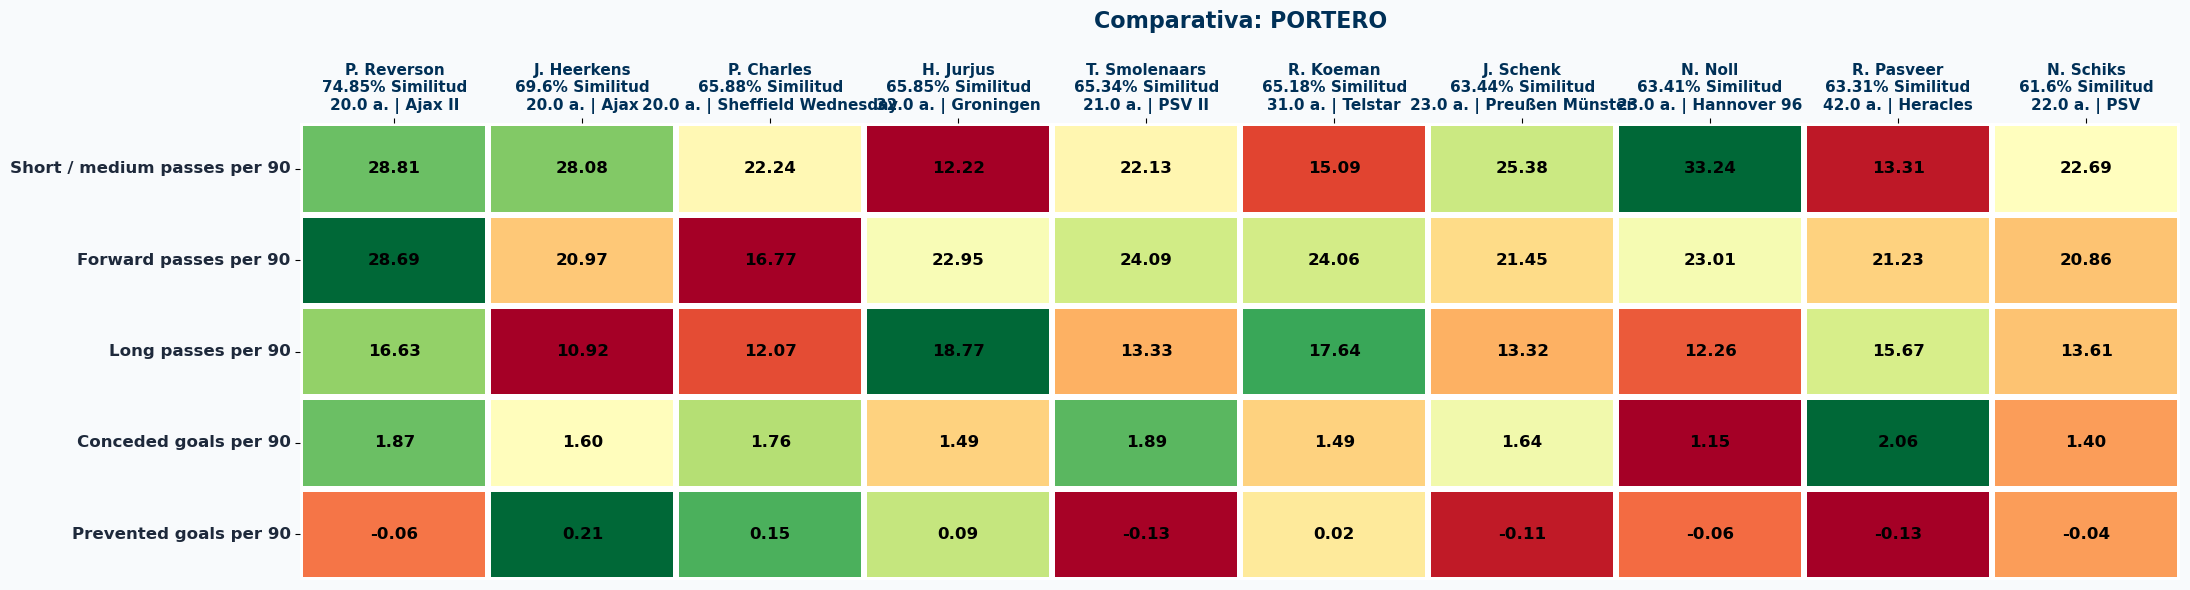


ANALIZANDO DEMARCACIÓN: LATERAL (LI|LB)


,Jugador,Equipo,Edad,Valor_MEur,Fin_Contrato,Carpeta_Origen,Score_Fit,Conducciones_Progresivas_P90,Centros_P90,Pases_Ultimo_Tercio_P90,Duelos_Defensivos_P90,Interceptaciones_P90
2061,G. Bolk,Emmen,21.0,0.0,2026-06-30,ligas,54.07,2.44,1.06,10.89,8.39,4.94
1470,K. Wagner,Birmingham City,29.0,0.0,2028-06-30,ligas,53.52,1.20,5.01,8.56,7.36,4.75
3986,Álex Calvo,FC Andorra,22.0,0.0,2028-06-30,ligas,52.94,3.87,4.69,2.34,9.38,3.52
3213,C. Konaté,Kifissia,22.0,0.0,2027-06-30,sub_23,52.74,2.71,4.55,5.35,7.58,4.55
3779,T. Baeten,Go Ahead Eagles,23.0,0.0,2029-06-30,ligas,52.73,3.97,6.06,1.88,7.94,2.82
4223,K. Inge,AZ II,20.0,0.0,2027-06-30,sub_23,52.37,5.10,1.74,4.29,8.58,3.49
3511,A. Sicker,Arminia Bielefeld,29.0,0.3,2026-06-30,ligas,51.79,2.38,2.84,8.15,5.95,5.68
1258,B. van Duijl,AZ,20.0,0.0,2031-06-30,sub_23,51.12,3.19,0.36,12.89,4.03,4.27
763,L. de Blok,VVV Venlo,21.0,0.0,2027-06-30,sub_23,50.22,1.90,3.96,5.66,8.30,5.08
1769,B. Moruzzi,Empoli,21.0,0.0,2027-06-30,sub_23,49.72,1.76,5.75,5.27,6.51,4.37


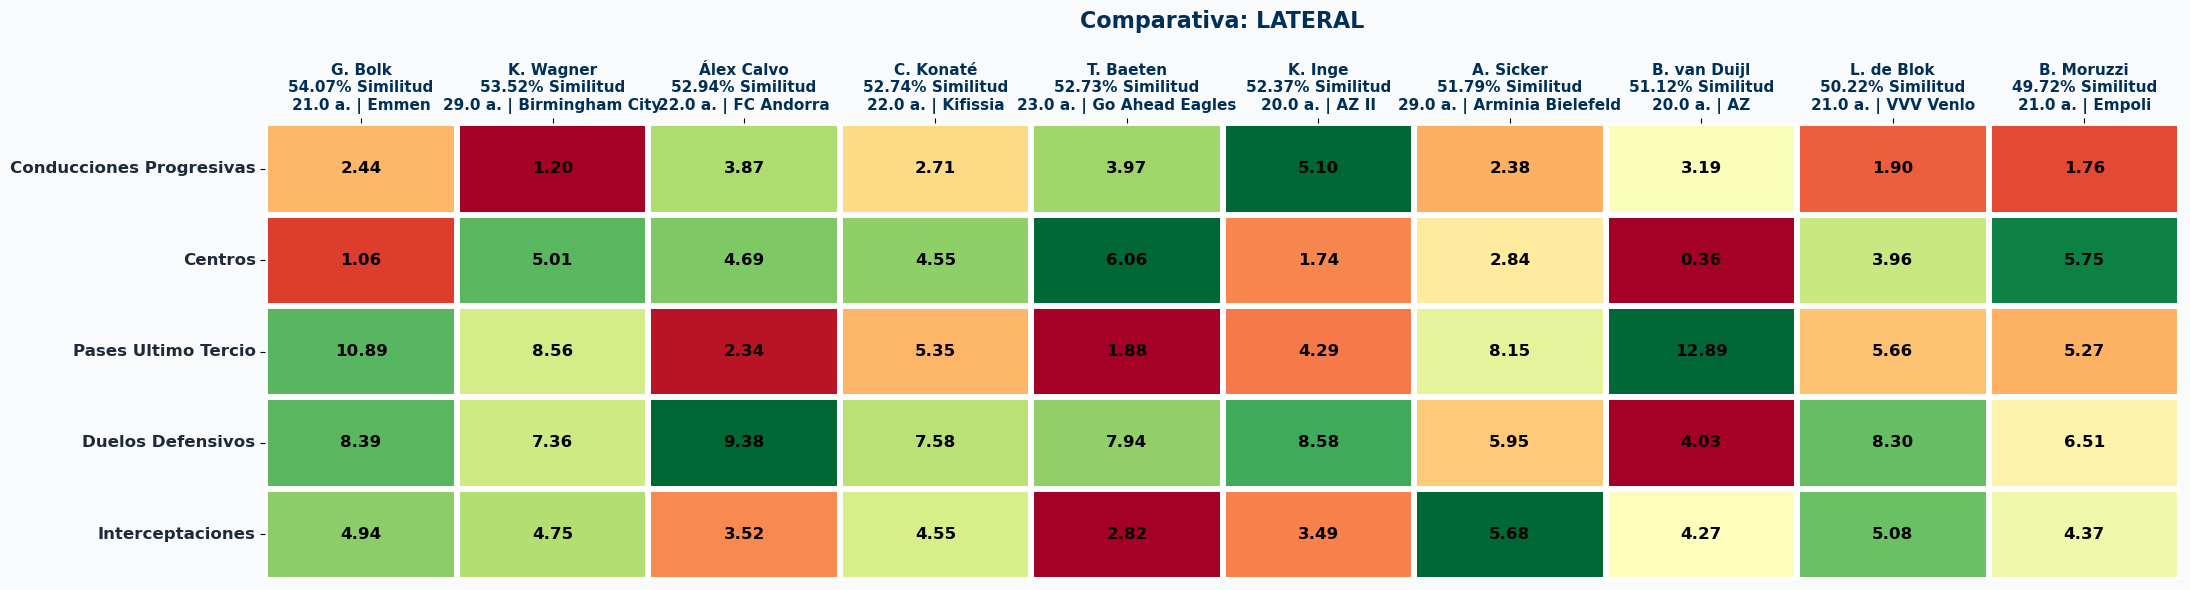


ANALIZANDO DEMARCACIÓN: DEFENSA CENTRAL (CB)


,Jugador,Equipo,Edad,Valor_MEur,Fin_Contrato,Carpeta_Origen,Score_Fit,Duelos_Defensivos_P90,Interceptaciones_P90,Duelos_Aereos_P90,Pases_Ultimo_Tercio_P90,Conducciones_Progresivas_P90
4169,P. Søndergaard,Emmen,19.0,0.00,2027-06-30,sub_23,73.79,9.35,5.58,6.23,8.70,2.21
100,Gael Alonso,FC Andorra,23.0,0.15,2028-06-30,ligas,63.86,6.47,5.95,5.72,9.89,1.81
276,C. Doyle,Wrexham,22.0,0.00,2029-06-30,sub_23,63.68,5.79,6.53,6.67,9.75,1.03
4329,M. Guidi,Cesena,22.0,0.00,2028-06-30,sub_23,63.58,9.68,6.21,3.76,6.07,0.58
2061,G. Bolk,Emmen,21.0,0.00,2026-06-30,ligas,62.89,8.39,4.94,3.03,10.89,2.44
4002,Henrique Trevisan,Tokyo,28.0,0.50,2025-12-31,ligas,62.20,6.14,5.43,8.74,7.68,0.83
2109,J. Hubner,Fortuna Sittard,22.0,0.00,2028-06-30,ligas,60.47,6.92,7.19,4.59,6.05,0.76
4273,C. McGhee,Sheffield Wednesday U21,20.0,0.00,2027-06-30,sub_23,60.33,10.00,5.69,4.31,3.47,0.42
736,T. Quintero,Sparta Rotterdam,27.0,0.00,2027-06-30,ligas,60.07,7.53,5.89,4.30,5.21,2.29
2317,L. Quenabio,Rodez,25.0,0.00,2026-06-30,ligas,59.91,8.63,5.07,5.07,6.30,1.11


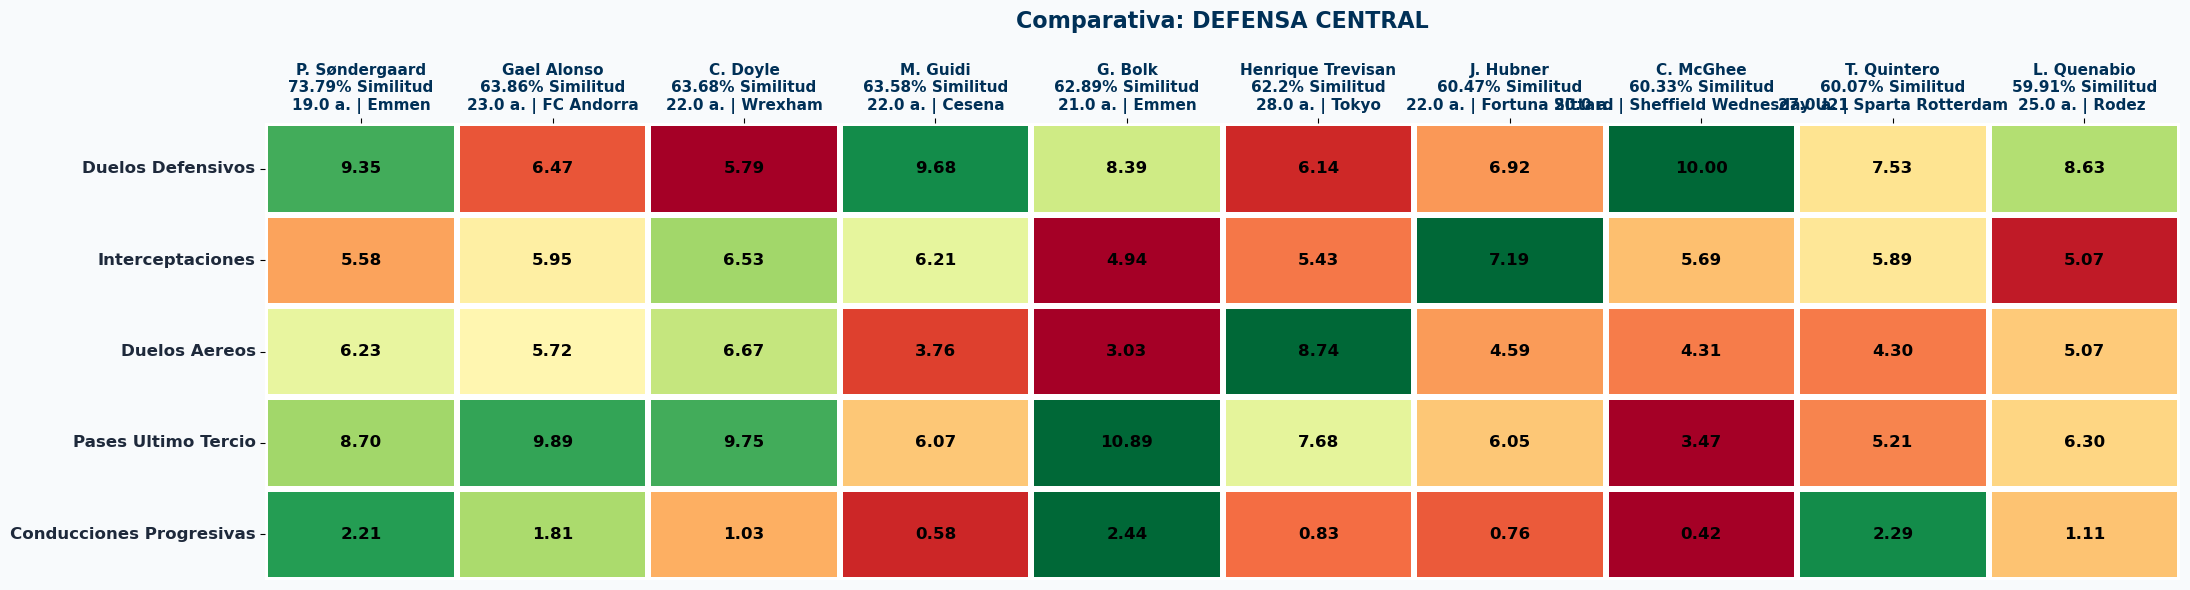


ANALIZANDO DEMARCACIÓN: MEDIOCENTRO (CMF|DMF)


,Jugador,Equipo,Edad,Valor_MEur,Fin_Contrato,Carpeta_Origen,Score_Fit,Pases_Ultimo_Tercio_P90,Forward passes per 90,Duelos_Defensivos_P90,Interceptaciones_P90,Conducciones_Progresivas_P90
478,Manu Molina,Eldense,34.0,0.3,2026-06-30,ligas,63.82,12.23,28.81,4.99,2.96,1.26
3144,M. Jiménez,ADO Den Haag,23.0,0.3,2028-06-30,sub_23,63.22,10.18,18.34,9.33,3.96,1.40
2450,G. Brugman,Pescara,33.0,2.0,2026-06-30,ligas,62.79,10.73,21.40,6.77,5.18,1.04
4342,M. Verkuijl,Ajax II,20.0,0.0,2029-06-30,sub_23,62.31,9.31,18.32,8.00,6.69,0.73
4545,Zidane Iqbal,Utrecht,23.0,1.0,2027-06-30,sub_23,62.08,10.71,16.73,7.86,3.68,2.51
4335,D. Demme,Hertha BSC,34.0,0.8,2026-06-30,ligas,61.93,10.71,25.03,6.80,3.04,1.30
2183,N. Lavi,Machida Zelvia,29.0,1.2,0,ligas,61.57,9.84,17.90,8.23,4.45,1.72
1098,K. Kaïboué,Amiens SC,27.0,1.0,2026-06-30,ligas,59.80,9.71,23.51,6.24,4.31,1.21
2602,W. Clem,København,21.0,1.8,2027-06-30,sub_23,59.01,9.35,18.05,7.17,5.83,0.77
1873,J. Meltofte Janssen,Nordsjælland U21,19.0,0.0,2030-06-30,sub_23,57.99,11.31,18.25,7.33,3.25,0.39


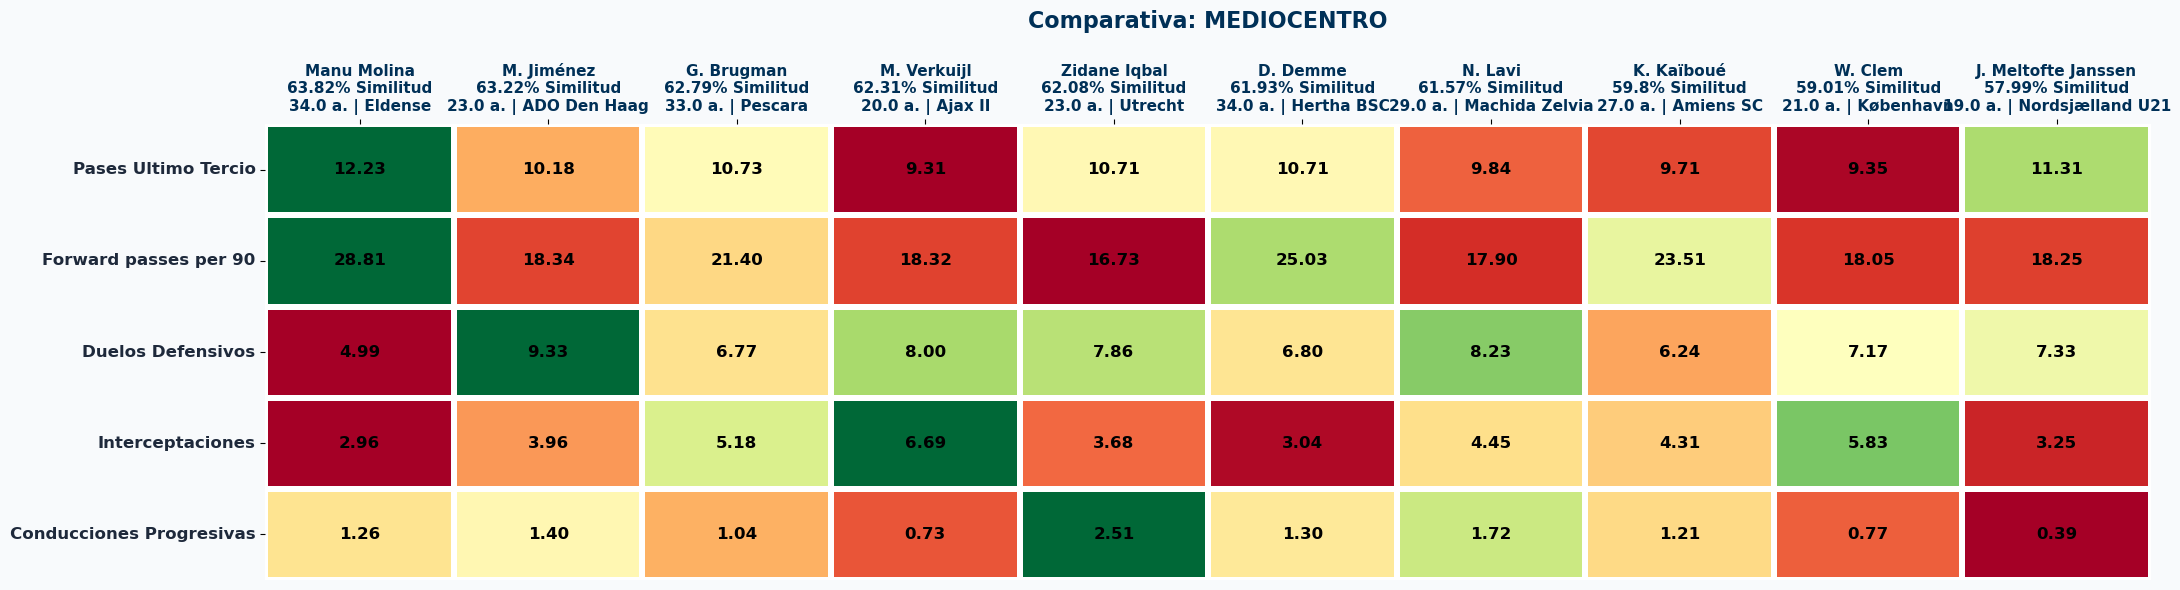


ANALIZANDO DEMARCACIÓN: MEDIOCENTRO OFENSIVO (AMF)


,Jugador,Equipo,Edad,Valor_MEur,Fin_Contrato,Carpeta_Origen,Score_Fit,Pases_Ultimo_Tercio_P90,Pases_Clave_P90,Conducciones_Progresivas_P90,Regates_P90,xA_P90
4162,Y. Benhattab,Reims,23.0,0.00,2028-06-30,sub_23,66.86,5.05,1.29,6.47,8.16,0.31
4321,N. Emeran,Emmen,23.0,0.25,2027-06-30,sub_23,65.73,2.30,1.87,4.31,11.05,0.36
4618,R. Fage,RKC Waalwijk,22.0,0.00,2028-06-30,sub_23,63.90,7.03,1.23,4.92,4.57,0.38
4633,C. Bischoff,Salzburg,20.0,0.00,2029-06-30,sub_23,59.37,2.13,1.25,6.23,8.36,0.40
1298,S. Ørjasæter,Twente,22.0,0.00,2029-06-30,ligas,59.23,1.98,1.38,6.52,7.89,0.32
716,I. Ferrah,Cambuur,20.0,0.00,2027-06-30,sub_23,58.60,4.37,1.10,5.54,9.18,0.18
192,Cristian Carracedo,Córdoba,30.0,0.40,2028-06-30,ligas,58.48,4.13,1.29,5.61,5.86,0.30
3076,A. Aouchiche,Schalke 04,23.0,0.00,2027-06-30,sub_23,55.50,5.00,0.98,4.02,6.06,0.44
3242,Y. Namli,PEC Zwolle,31.0,0.00,2028-06-30,ligas,55.31,5.82,0.89,4.36,5.57,0.36
332,M. Godts,Ajax,20.0,0.00,2029-06-30,ligas,54.63,3.84,1.14,5.42,6.38,0.24


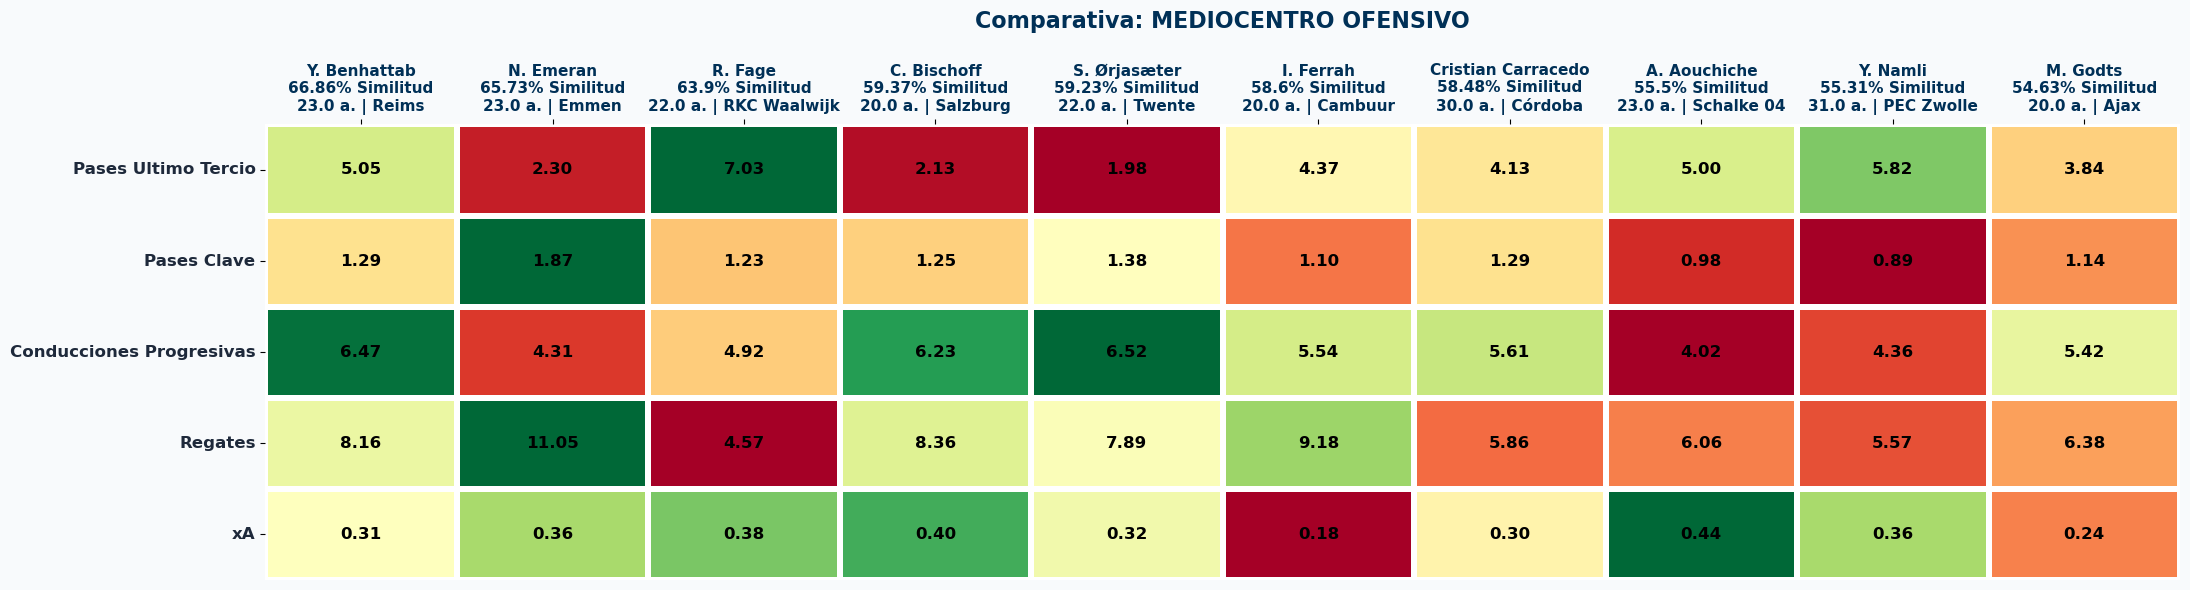


ANALIZANDO DEMARCACIÓN: EXTREMO (RW|LW)


,Jugador,Equipo,Edad,Valor_MEur,Fin_Contrato,Carpeta_Origen,Score_Fit,Regates_P90,Conducciones_Progresivas_P90,Centros_P90,xA_P90,Toques_Area_P90
3566,M. Bahaty,PSV II,18.0,0.00,2028-06-30,sub_23,77.73,8.44,7.22,6.00,0.17,5.25
4633,C. Bischoff,Salzburg,20.0,0.00,2029-06-30,sub_23,77.65,8.36,6.23,4.09,0.40,5.34
3760,F. Emmery,AGF,19.0,0.00,2029-06-30,sub_23,77.19,9.09,5.89,4.96,0.25,5.99
4162,Y. Benhattab,Reims,23.0,0.00,2028-06-30,sub_23,77.02,8.16,6.47,6.60,0.31,4.14
3721,Alisson Santos,Napoli,23.0,0.15,2030-06-30,sub_23,76.83,9.12,7.20,4.16,0.10,6.39
1298,S. Ørjasæter,Twente,22.0,0.00,2029-06-30,ligas,75.36,7.89,6.52,2.99,0.32,6.43
2095,J. Kadile,Servette,23.0,0.00,0,sub_23,73.73,8.76,7.04,3.60,0.17,5.27
4520,O. Zimuangana,Helmond Sport,20.0,0.00,2026-06-30,ligas,73.62,9.84,4.75,6.72,0.24,3.93
4046,Y. van der Veen,RKC Waalwijk,20.0,0.00,2029-06-30,sub_23,73.00,8.74,6.32,6.19,0.18,3.89
3866,D. Lukébakio,Benfica,28.0,0.00,2030-06-30,ligas,71.23,7.75,4.70,5.24,0.38,5.02


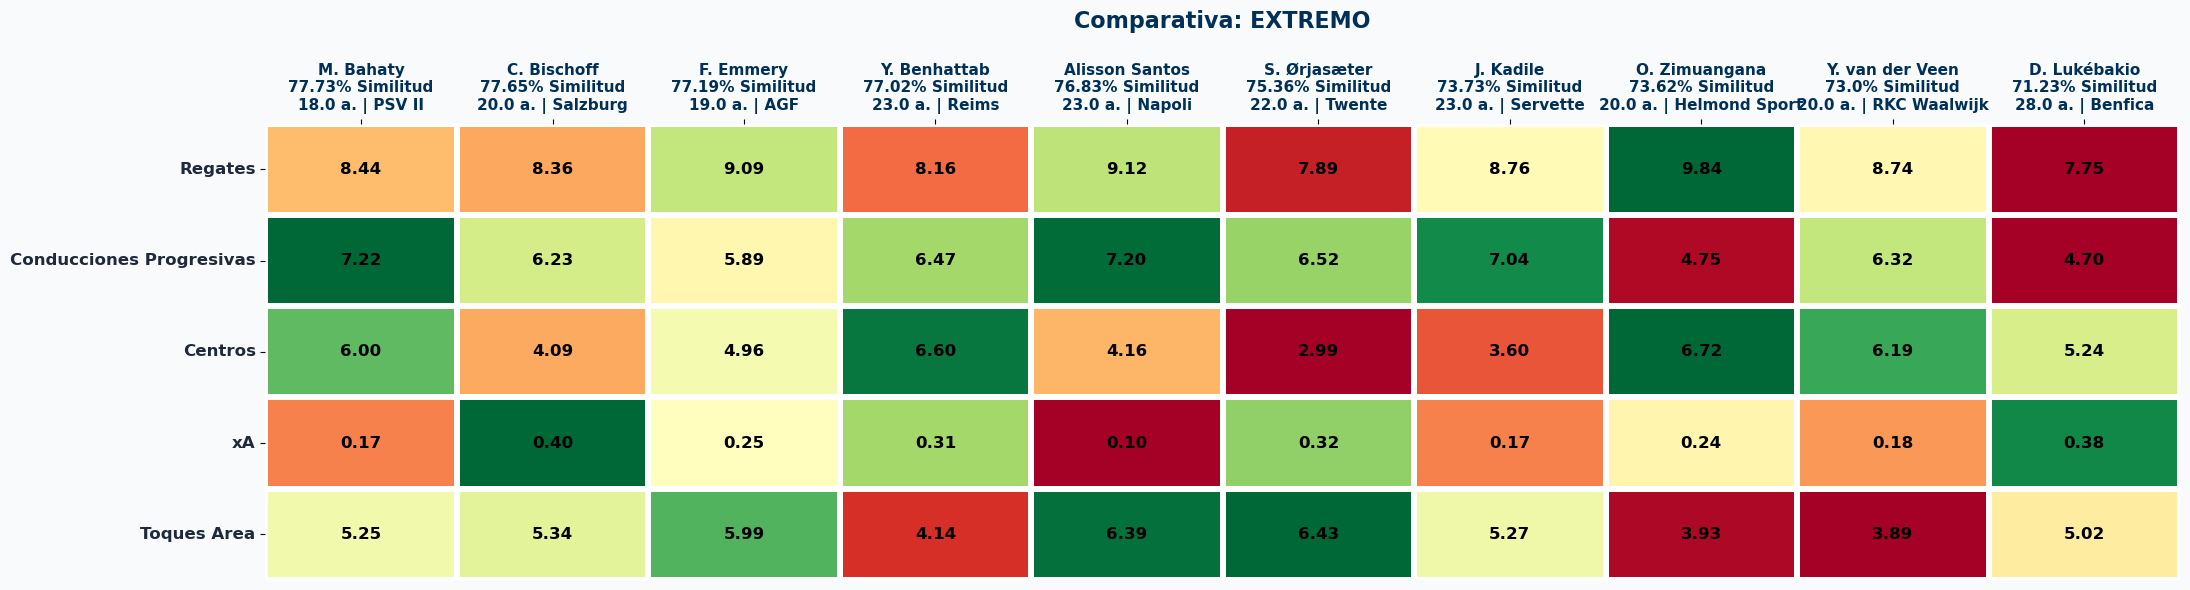


ANALIZANDO DEMARCACIÓN: DELANTERO CENTRO (CF)


,Jugador,Equipo,Edad,Valor_MEur,Fin_Contrato,Carpeta_Origen,Score_Fit,Goles_P90,xG_P90,Toques_Area_P90,Remates_P90,Duelos_Ofensivos_P90
4387,N. Ohio,Real Valladolid,23.0,2.0,2027-06-30,sub_23,84.15,1.35,0.79,4.04,4.04,9.12
4322,B. Kovacs,AZ U19,19.0,0.0,2028-06-30,sub_23,77.21,1.15,0.58,4.59,3.88,15.65
480,L. Suárez,Sporting CP,28.0,0.0,2030-06-30,ligas,76.88,0.86,0.79,5.74,3.95,9.26
2688,T. Van Der Leij,RKC Waalwijk,20.0,0.0,2028-06-30,sub_23,74.62,0.85,0.68,5.90,3.67,12.32
4116,J. Cueto,Real Avilés,25.0,0.2,2026-06-30,ligas,71.54,1.14,0.70,3.92,3.16,5.69
2445,Bouke Boersma,Mechelen,20.0,0.0,2029-06-30,sub_23,69.08,0.73,0.81,4.74,2.98,10.27
2380,R. Pepi,PSV,23.0,0.0,2030-06-30,ligas,68.97,0.95,0.62,5.47,3.21,5.11
1476,T. Bentayeb,Troyes,24.0,0.0,2026-06-30,ligas,66.15,0.77,0.74,4.68,3.43,5.32
2414,Samu Omorodion,Porto,21.0,0.0,2029-06-30,ligas,65.91,0.78,0.74,3.90,3.06,10.87
2640,Y. Moukoko,København,21.0,0.0,2030-06-30,sub_23,65.81,0.71,0.69,4.85,3.62,8.67


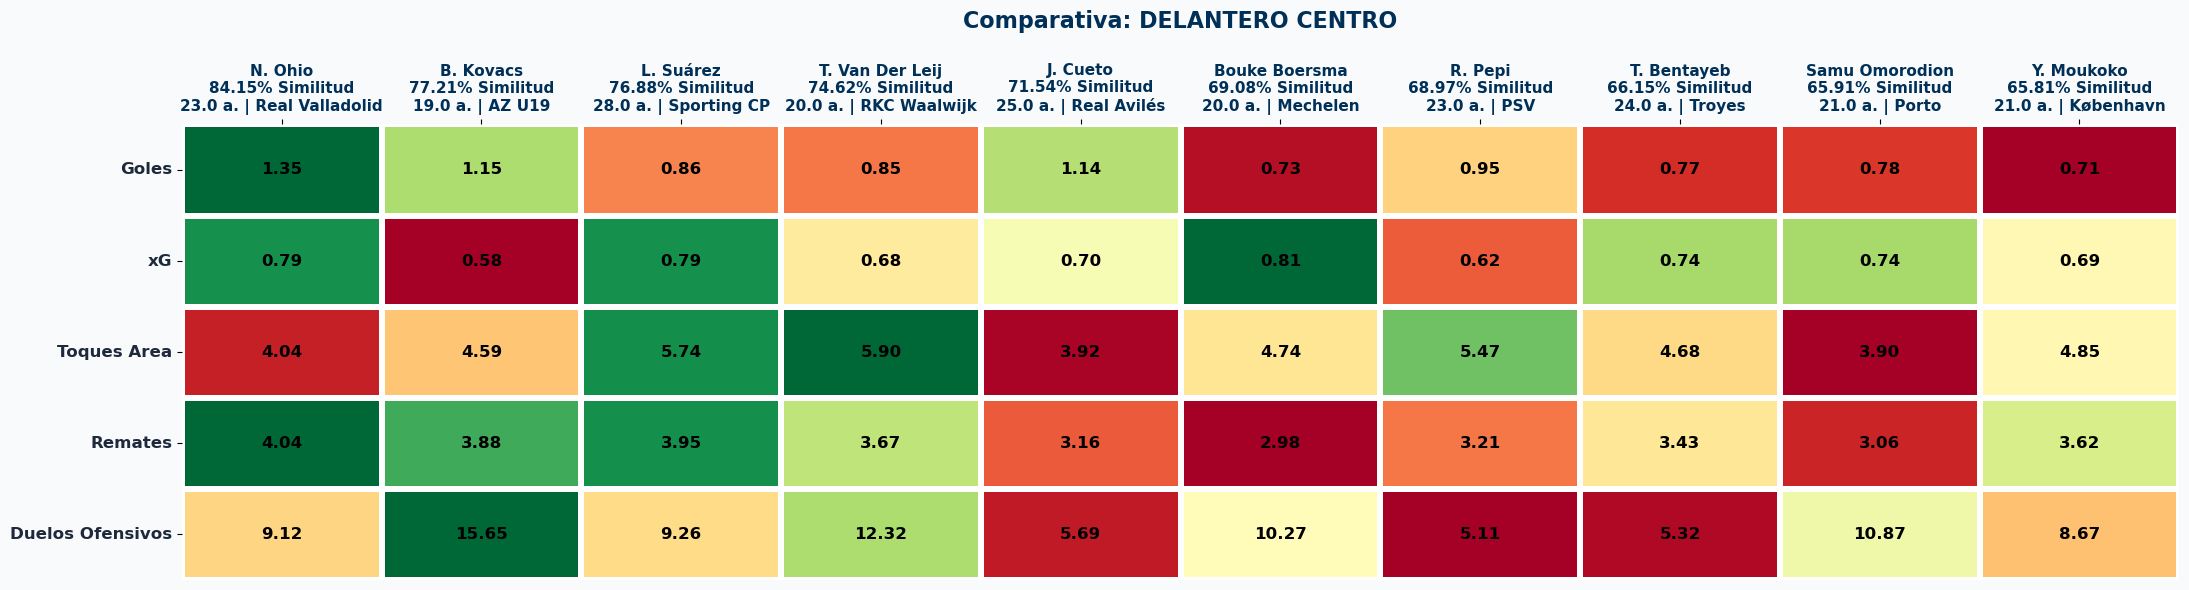


Exportación realizada: 70 opciones guardadas en 'top_opciones_mercado_2627.csv'


In [ ]:
# Crear el directorio destino
ruta_seleccion = Path.cwd().parent.parent / 'data' / 'seleccion'
ruta_seleccion.mkdir(parents=True, exist_ok=True)

lista_top_mercado = []

if 'df_mercado_viable' in locals() and not df_mercado_viable.empty:
    for siglas, nombre_perfil in POSICIONES_BUSQUEDA:
        print(f"\n{'='*90}")
        print(f"ANALIZANDO DEMARCACIÓN: {nombre_perfil.upper()} ({siglas})")
        print(f"{'='*90}")
        
        # Obtener el DataFrame con el motor de búsqueda
        top_10 = buscar_top_10_mercado(df_mercado_viable, siglas, nombre_perfil, PERFILES_OBJETIVO)
        
        if not top_10.empty:
            # Etiquetar el perfil para la base de datos final
            top_10['Perfil_Buscado'] = nombre_perfil
            lista_top_mercado.append(top_10)
            
            # Mostrar el DataFrame
            display(top_10.iloc[:, :-1])
            
            # Generar el panel visual
            candidatos_vis = top_10.head(10)
            metricas_perfil = PERFILES_OBJETIVO[nombre_perfil]['metricas']
            graficar_heatmap_candidatos(candidatos_vis, metricas_perfil, nombre_perfil)
            
        else:
            print(f"No se encontraron candidatos viables para la posición de {nombre_perfil}.")

# Consolidar y exportar
if lista_top_mercado:
    df_seleccion_final = pd.concat(lista_top_mercado, ignore_index=True)
    ruta_exportacion = ruta_seleccion / 'top_opciones_mercado_2627.csv'
    df_seleccion_final.to_csv(ruta_exportacion, index=False, encoding='utf-8-sig')
    print("\n" + "="*90)
    print(f"Exportación realizada: {len(df_seleccion_final)} opciones guardadas en '{ruta_exportacion.name}'")
    print("="*90)